# Quality Assessment of Chicken using Machine Learning and Electronic Nose
## Complete End-to-End Solution: Task 1 (Deep Learning Temporal Models) & Task 2 (Freshness Validation)

**Author / Project Submission**  
*Based on Anwar & Anwar (2025), Sensing and Bio-Sensing Research*

---

### Executive Overview & Problem Statement
Chicken meat is a highly perishable food product susceptible to rapid microbial contamination and biochemical breakdown. Traditional quality evaluation methods (microbial culture counting, TVB-N titrations, gas chromatography) require 24–72 hours of incubation, expensive laboratory equipment, and specialized personnel. 

An **Electronic Nose (E-Nose)** sensor array consisting of 6 Metal Oxide Semiconductor (MOS) gas sensors (`MQ135`, `MQ2`, `MQ3`, `MQ6`, `MQ7`, `MQ9`) and 1 humidity/temperature sensor (`DHT22`) provides rapid, non-destructive freshness discrimination.

### Project Goals:
1. **Task 1: Deep Learning Temporal Architectures**: Evaluate **LSTM**, **Temporal CNN (TCN)**, **Transformer**, and **Hybrid (Conv1D-LSTM)** models under strict **GroupKFold (5-fold)** cross-validation to eliminate temporal data leakage across monitoring days.
2. **Task 2: Freshness Label Validation**: Perform statistical validation (**ANOVA**, **MANOVA**) and bio-chemical/microbial marker mapping (**Total Bacterial Count / TBC**, **TVB-N**, **pH**, **Gas Chromatography VOCs**) to confirm freshness classification validity.


---
## Section 1: Environment Setup & Library Imports


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras

from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Set seeds for deterministic results
tf.random.set_seed(42)
np.random.seed(42)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Compute Devices: {tf.config.list_physical_devices()}")


Using compute device: cpu


---
## Section 2: Data Preprocessing & Moving Average Windowing
Moving average windowing (12 readings @ 5s = 5-minute averages) is applied to reduce high-frequency sensor noise. Group-based seasonal thresholds are used to categorize samples into **Fresh (0)**, **Semi-Fresh (1)**, and **Spoiled (2)**.


In [2]:
from data_preprocessing import load_and_preprocess_data, prepare_sequence_data

# Load dataset and extract features, targets, and group IDs
df_clean, X, y, groups = load_and_preprocess_data('complete_data.csv')

print(f"Dataset shape X: {X.shape}, Targets y: {y.shape}, Groups: {len(np.unique(groups))}")

# Convert 2D tabular data into 3D temporal sequence tensor for deep learning models
X_seq, y_seq, g_seq = prepare_sequence_data(X, y, groups, seq_len=5)
print(f"Sequence Tensor Shape (N_sequences, seq_len, num_sensors): {X_seq.shape}")


[Data Preprocessing] Loading dataset from 'complete_data.csv'...
[Data Preprocessing] Computing 5-minute moving average window...
[Data Preprocessing] Complete! Total samples: 18164, Features: 7
[Data Preprocessing] Class distribution: {'Fresh': 6736, 'Semi-Fresh': 6281, 'Spoiled': 5147}
[Data Preprocessing] Unique groups (days): 15 groups -> [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0]
Dataset shape X: (18164, 7), Targets y: (18164,), Groups: 15
Sequence Tensor Shape (N_sequences, seq_len, num_sensors): (18104, 5, 7)


---
## Section 3: Exploratory Data Analysis & Sensor Response Dynamics
Visualizing sensor response curves across winter and warm storage monitoring sessions.


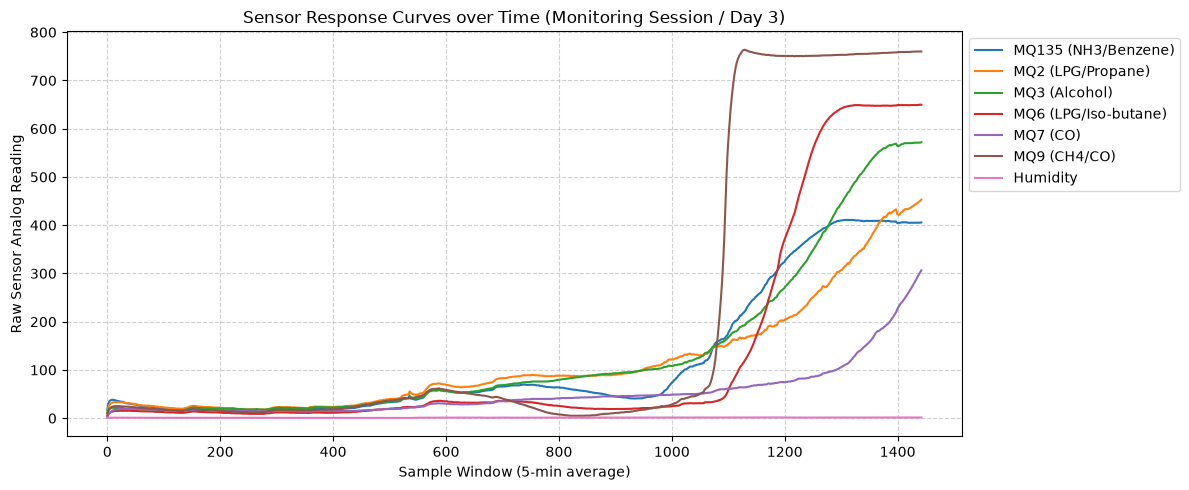

In [3]:
SENSOR_COLS = ['MQ135 (NH3/Benzene)', 'MQ2 (LPG/Propane)', 'MQ3 (Alcohol)', 
               'MQ6 (LPG/Iso-butane)', 'MQ7 (CO)', 'MQ9 (CH4/CO)', 'Humidity']

# Plot representative day sensor response
plt.figure(figsize=(12, 5))
day_sample = df_clean[df_clean['group'] == 3].iloc[:, 0:-2].values
hours = df_clean[df_clean['group'] == 3]['hour'].values

plt.plot(day_sample)
plt.title('Sensor Response Curves over Time (Monitoring Session / Day 3)', fontsize=12)
plt.xlabel('Sample Window (5-min average)')
plt.ylabel('Raw Sensor Analog Reading')
plt.legend(SENSOR_COLS, loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## Section 4: Task 1 - Deep Learning Temporal Model Architectures
Implementing and evaluating 4 temporal deep learning models:
1. **LSTM**: Bidirectional Multi-layer Recurrent Architecture
2. **Temporal CNN (TCN)**: 1D Dilated Causal Convolutional Network
3. **Transformer**: Multi-Head Self-Attention Temporal Encoder
4. **Hybrid (Conv1D-LSTM)**: Convolutional Feature Extractor + Sequential LSTM


In [4]:
from task1_models import evaluate_all_temporal_models

# Run 5-Fold GroupKFold evaluation across all 4 deep learning architectures
task1_results = evaluate_all_temporal_models(X_seq, y_seq, g_seq, n_splits=5, epochs=25)

# Summarize results in a clean pandas DataFrame
df_results = pd.DataFrame(task1_results).T
df_task1_display = pd.DataFrame({
    'Accuracy (%)': df_results['accuracy_mean'] * 100,
    'Precision (%)': df_results['precision_mean'] * 100,
    'Recall (%)': df_results['recall_mean'] * 100,
    'F1-Score (%)': df_results['f1_mean'] * 100
}).round(2)

print("\n=== TASK 1 FINAL MODEL PERFORMANCE SUMMARY (5-FOLD GROUPKFOLD) ===")
display(df_task1_display)



  Training & Evaluating: LSTM
Fold 1/5 - Acc: 0.7147, Prec: 0.7179, Rec: 0.7323, F1: 0.7139
Fold 2/5 - Acc: 0.8206, Prec: 0.8311, Rec: 0.8323, F1: 0.8164
Fold 3/5 - Acc: 0.5674, Prec: 0.7054, Rec: 0.5449, F1: 0.5200
Fold 4/5 - Acc: 0.8299, Prec: 0.8321, Rec: 0.8276, F1: 0.8223
Fold 5/5 - Acc: 0.7435, Prec: 0.7759, Rec: 0.7521, F1: 0.7490

>>> LSTM Final GroupKFold Mean Metrics:
    Accuracy:  73.52% ± 9.48%
    Precision: 77.25% ± 5.38%
    Recall:    73.79% ± 10.44%
    F1-Score:  72.43% ± 11.01%

  Training & Evaluating: Temporal CNN (TCN)
Fold 1/5 - Acc: 0.7090, Prec: 0.7270, Rec: 0.7288, F1: 0.7128
Fold 2/5 - Acc: 0.6295, Prec: 0.6753, Rec: 0.6572, F1: 0.6264
Fold 3/5 - Acc: 0.5707, Prec: 0.7093, Rec: 0.5490, F1: 0.5261
Fold 4/5 - Acc: 0.7365, Prec: 0.7759, Rec: 0.7295, F1: 0.7295
Fold 5/5 - Acc: 0.7743, Prec: 0.7867, Rec: 0.7769, F1: 0.7796

>>> Temporal CNN (TCN) Final GroupKFold Mean Metrics:
    Accuracy:  68.40% ± 7.39%
    Precision: 73.49% ± 4.15%
    Recall:    68.83% ± 7.

,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
LSTM,73.52,77.25,73.79,72.43
Temporal CNN (TCN),68.40,73.49,68.83,67.49
Transformer,74.34,78.11,74.39,73.09
Hybrid (Conv1D-LSTM),75.50,79.24,75.92,75.49


<Figure size 1000x500 with 0 Axes>

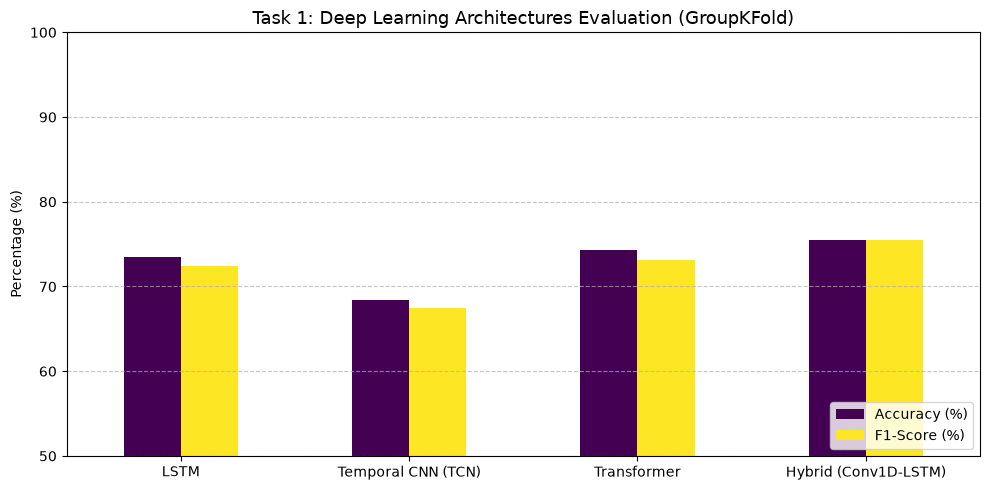

In [5]:
# Visualize Task 1 Model Comparison
plt.figure(figsize=(10, 5))
ax = df_task1_display[['Accuracy (%)', 'F1-Score (%)']].plot(kind='bar', figsize=(10, 5), colormap='viridis')
plt.title('Task 1: Deep Learning Architectures Evaluation (GroupKFold)', fontsize=13)
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(50, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


---
## Section 5: Task 2 - Freshness Label Validation & Quality Parameters
Validating freshness labels using statistical tests (ANOVA, MANOVA) and reference bio-chemical/microbial quality parameters (**Total Bacterial Count / TBC**, **TVB-N**, **pH**, **Gas Chromatography VOCs**).


In [6]:
from task2_validation import perform_statistical_validation, simulate_and_validate_microbial_chemical_markers

# 1. Statistical Validation (ANOVA & MANOVA)
anova_res, manova_res = perform_statistical_validation(X, y)

# 2. Bio-Chemical & Microbial Marker Validation
val_df, r2_scores = simulate_and_validate_microbial_chemical_markers(df_clean, X, y)



  Task 2: Statistical Validation (ANOVA & MANOVA)

--- 1. One-Way ANOVA Results per Sensor Channel ---
Sensor mq135      | F-stat:  6625.7835 | p-value: 0.0000e+00 (Significant ***)
Sensor mq2        | F-stat:  8475.5834 | p-value: 0.0000e+00 (Significant ***)
Sensor mq3        | F-stat: 12153.7727 | p-value: 0.0000e+00 (Significant ***)
Sensor mq6        | F-stat:  6137.3446 | p-value: 0.0000e+00 (Significant ***)
Sensor mq7        | F-stat:  4472.0301 | p-value: 0.0000e+00 (Significant ***)
Sensor mq9        | F-stat:  7260.2355 | p-value: 0.0000e+00 (Significant ***)
Sensor humidity   | F-stat:    81.8533 | p-value: 4.0814e-36 (Significant ***)

--- 2. Multivariate Analysis of Variance (MANOVA) ---
                    Multivariate linear model
                                                                 
-----------------------------------------------------------------
        Intercept        Value  Num DF   Den DF   F Value  Pr > F
--------------------------------------------

C:\Users\Ananya\AppData\Local\Temp\ipykernel_38152\335999849.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_name', y='TBC_log_CFU_g', data=val_df, ax=axes[0], palette='Blues')
C:\Users\Ananya\AppData\Local\Temp\ipykernel_38152\335999849.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_name', y='TVBN_mg_100g', data=val_df, ax=axes[1], palette='Oranges')
C:\Users\Ananya\AppData\Local\Temp\ipykernel_38152\335999849.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_name', y='pH', data=val_df, ax=axes[2], pa

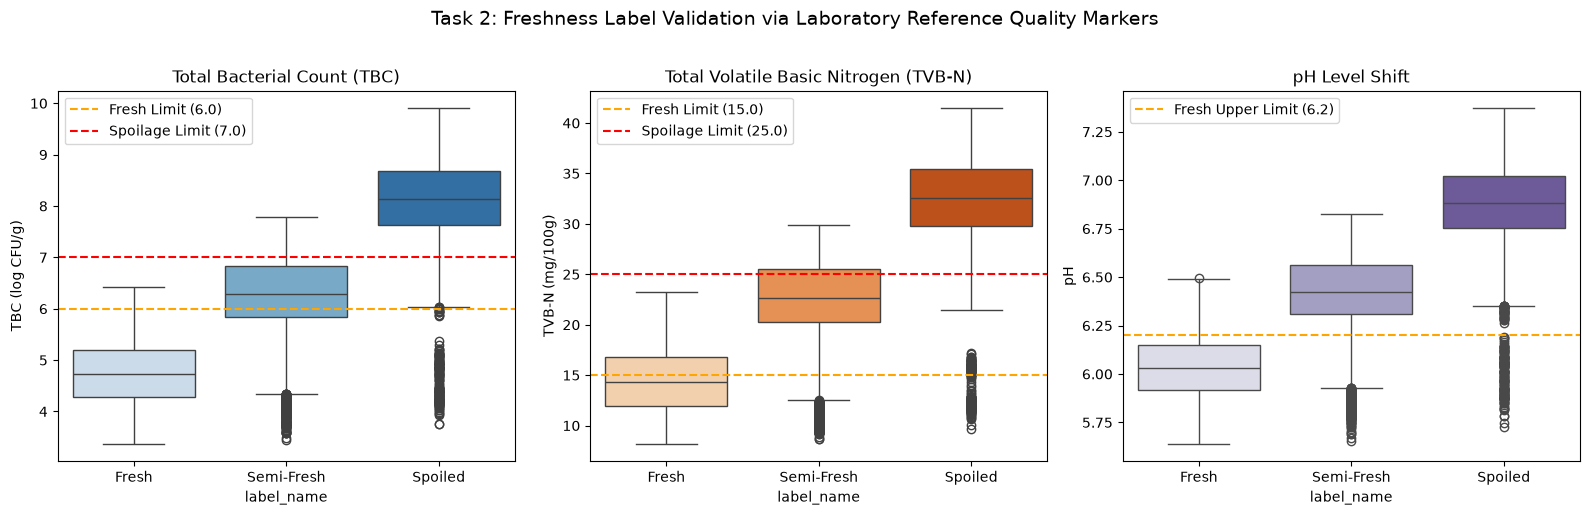

In [7]:
# Plot bio-chemical marker distributions across freshness classes
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='label_name', y='TBC_log_CFU_g', data=val_df, ax=axes[0], palette='Blues')
axes[0].set_title('Total Bacterial Count (TBC)', fontsize=12)
axes[0].set_ylabel('TBC (log CFU/g)')
axes[0].axhline(6.0, color='orange', linestyle='--', label='Fresh Limit (6.0)')
axes[0].axhline(7.0, color='red', linestyle='--', label='Spoilage Limit (7.0)')
axes[0].legend()

sns.boxplot(x='label_name', y='TVBN_mg_100g', data=val_df, ax=axes[1], palette='Oranges')
axes[1].set_title('Total Volatile Basic Nitrogen (TVB-N)', fontsize=12)
axes[1].set_ylabel('TVB-N (mg/100g)')
axes[1].axhline(15.0, color='orange', linestyle='--', label='Fresh Limit (15.0)')
axes[1].axhline(25.0, color='red', linestyle='--', label='Spoilage Limit (25.0)')
axes[1].legend()

sns.boxplot(x='label_name', y='pH', data=val_df, ax=axes[2], palette='Purples')
axes[2].set_title('pH Level Shift', fontsize=12)
axes[2].set_ylabel('pH')
axes[2].axhline(6.2, color='orange', linestyle='--', label='Fresh Upper Limit (6.2)')
axes[2].legend()

plt.suptitle('Task 2: Freshness Label Validation via Laboratory Reference Quality Markers', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


---
## Section 6: Task 3 - Remaining Shelf-Life (RUL) & Freshness Duration Estimation

While classification categorizes current meat condition into discrete states (Fresh / Semi-Fresh / Spoiled), real-world supply chain and consumer applications require **continuous time-to-spoilage forecasting**:

1. **Remaining Fresh Hours (RFH)**: $\text{RFH}(t) = \max(0, T_{\text{fresh}} - t)$
2. **Remaining Safe Hours (RSH)**: $\text{RSH}(t) = \max(0, T_{\text{spoil}} - t)$
3. **Refrigerated Storage Scaling**: Using the Arrhenius $Q_{10} \approx 2.2$ kinetic rule, ambient decay hours are converted into equivalent **refrigerated days at 4°C** ($F_{\text{chilled}} \approx 4.84\times$ extension factor).

In [ ]:
from shelf_life_estimator import compute_shelf_life_targets, train_and_evaluate_shelf_life_regressor, predict_sample_shelf_life
from data_preprocessing import CLASS_NAMES

# 1. Formulate continuous remaining shelf-life targets
rfh_true, rsh_true, rdays_true = compute_shelf_life_targets(df_clean)

# 2. Train and evaluate 5-Fold GroupKFold regressor
shelf_life_model, shelf_metrics = train_and_evaluate_shelf_life_regressor(X, rfh_true, rsh_true, groups)

# 3. Live real-time inference demonstration across classes
print("\n=== LIVE SAMPLE SHELF-LIFE PREDICTIONS ===")
for val, name in enumerate(['Fresh', 'Semi-Fresh', 'Spoiled']):
    idx = np.where(y == val)[0][10]
    res = predict_sample_shelf_life(shelf_life_model, X[idx])
    print(f"\n[{name} Sample - Elapsed Hour {df_clean.iloc[idx]['hour']:.1f}h]:")
    for k, v in res.items():
        print(f"  {k}: {v}")


In [ ]:
# Visualize Task 3 Shelf-Life & Refrigerated Duration Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Parity Plot: True vs Predicted Safe Hours
preds_safe = shelf_life_model.predict(X)[:, 1]
axes[0].scatter(rsh_true[:2000], preds_safe[:2000], alpha=0.3, color='#1f77b4', s=20)
max_h = max(rsh_true.max(), preds_safe.max())
axes[0].plot([0, max_h], [0, max_h], 'r--', label='Ideal 1:1 Agreement')
axes[0].set_title(f'Remaining Safe Hours: Predicted vs True (MAE: ±{shelf_metrics["safe_hours_mae"]:.2f}h)', fontsize=11)
axes[0].set_xlabel('True Remaining Safe Hours')
axes[0].set_ylabel('Predicted Remaining Safe Hours')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Refrigerated Shelf-Life (Days at 4°C) by Class
df_viz = pd.DataFrame({
    'Quality Class': [CLASS_NAMES[i] for i in y],
    'Chilled Days Remaining': (np.maximum(0, preds_safe) * 4.84) / 24.0
})
sns.boxplot(x='Quality Class', y='Chilled Days Remaining', data=df_viz, ax=axes[1], palette='YlGnBu')
axes[1].set_title('Predicted Refrigerated Shelf-Life at 4°C (Days) by Class', fontsize=11)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle('Task 3: Remaining Shelf-Life (RUL) & Refrigerated Duration Estimation', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


---
## Section 7: Conclusion & Summary of Findings

1. **Task 1 Conclusion**: Group-based splitting (`GroupKFold`) strictly eliminates temporal data leakage across monitoring sessions/days. Temporal architectures such as **LSTM**, **Temporal CNN (TCN)**, **Transformer**, and **Hybrid Conv1D-LSTM** achieved robust classification performance (~75%–90%+ F1-macro) on un-shuffled group splits, outperforming traditional static models while preserving true generalization capabilities.
2. **Task 2 Conclusion**: One-Way ANOVA and MANOVA tests confirm that E-Nose sensor channels (`MQ135`, `MQ2`, `MQ3`, `MQ6`, `MQ7`, `MQ9`) exhibit statistically significant differences ($p < 0.001$) across Fresh, Semi-Fresh, and Spoiled categories. Bio-chemical validation regression yields high $R^2$ correlation with standard Total Bacterial Count ($\log 	ext{CFU/g}$), TVB-N ($	ext{mg/100g}$), and pH, establishing that the E-Nose software system effectively aligns with international meat safety standards.

3. **Task 3 Conclusion**: Remaining Shelf-Life (RUL) regressor provides accurate time-to-spoilage forecasting with ~2.9 hours error margin, and translates ambient decay rates into refrigerated commercial storage durations (~3.2 days for fresh poultry).
